## 1 — Project overview

Detect and localize metal nut defects with a pretrained YOLOv8n detector and one
class, `defect`. Original defect categories remain in the analysis metadata.

The source notebook contains no invented results; execution creates the actual
tables and figures. The provided local dataset has been inspected and copied to
`data/metal_nut` (335 images and 93 masks; see `data/source.json`). For a fresh
installation, follow `data/README.md` to supply the original MVTec AD category.
This is a custom supervised **80% development / 20% test** experiment, not the
official anomaly-detection benchmark. Validation comes only from development.

Run all sections in order. Both experiments and the validation-based model choice
are completed in section 9 before test results are opened. Section 13 reports the
predeclared augmentation experiment; do not change it after seeing test failures.


## 2 — Import libraries

Reusable annotation, split, matching, and decoding functions live in `src/`.
Training, full-test evaluation, export, and timing remain visible here.


In [1]:
import importlib.metadata as metadata
import json
import os
import platform
import random
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import pandas as pd
import structlog
import torch
import yaml
from IPython.display import Markdown, display
from ultralytics import YOLO

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "dataset.py").is_file():
    raise RuntimeError(
        "Open this notebook from the project root or notebooks directory"
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.annotations import boxes_to_yolo, read_mask, yolo_to_boxes
from src.dataset import inspect_dataset, prepare_yolo, split_dataset, split_summary
from src.evaluation import box_iou, match_detections
from src.onnx_inference import decode, predict_onnx, preprocess
from src.utils import draw_boxes, measure_latency, read_rgb, save_figure

structlog.configure(
    processors=[
        structlog.processors.TimeStamper(fmt="iso"),
        structlog.processors.JSONRenderer(),
    ]
)
log = structlog.get_logger()

## 3 — Configuration

The 20% test portion is fixed before augmentation. Validation is 12.5% of the
80% development portion (approximately 10% of all images). Integer counts use
scikit-learn's rounding: test has `ceil(N * 0.20)` images.

The sole experiment change is horizontal reflection with probability 0.5.
This preserves every defect pixel, color, and visible nut face; it does not turn
a face-flipped nut into a good part. Rotation was excluded after inspecting
training boxes at image boundaries. Color jitter, mosaic, mixup and scaling are
disabled. Confidence and IoU settings are fixed before test evaluation.


In [2]:
DATASET_DIR = ROOT / "data" / "metal_nut"
OUTPUT_DIR = ROOT / "results"
SEED = 42
TRAIN_RATIO = 0.80
TEST_RATIO = 0.20
VAL_RATIO = 0.125  # Fraction of development, not of the complete dataset.
IMAGE_SIZE = 640
BATCH_SIZE = 16
EPOCHS = 50
MODEL = "yolov8n.pt"
DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORKERS = 0  # Reliable in Windows notebooks; increase only on suitable systems.
CPU_THREADS = min(4, os.cpu_count() or 1)
CONFIDENCE = 0.25
AP_CONFIDENCE = 0.001
MATCH_IOU = 0.50
NMS_IOU = 0.70
MAX_DETECTIONS = 300
MIN_MASK_AREA = 9
WARMUP_RUNS = 10
MEASURED_RUNS = 100

if DEVICE == "cpu":
    BATCH_SIZE = min(BATCH_SIZE, 4)
elif torch.cuda.get_device_properties(0).total_memory < 6 * 1024**3:
    BATCH_SIZE = min(BATCH_SIZE, 8)
assert np.isclose(TRAIN_RATIO + TEST_RATIO, 1)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(CPU_THREADS)
cv2.setNumThreads(1)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

BASE_AUGMENTATION = dict(
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.0,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
)
EXPERIMENTS = {
    "baseline": BASE_AUGMENTATION.copy(),
    "augmented": {**BASE_AUGMENTATION, "fliplr": 0.5},
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / "models").mkdir(exist_ok=True)
RUN_DIR = OUTPUT_DIR / "runs" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
DATA_YAML = ROOT / "configs" / "data.yaml"
config = {
    "seed": SEED,
    "train_ratio": TRAIN_RATIO,
    "test_ratio": TEST_RATIO,
    "validation_fraction_of_development": VAL_RATIO,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "model": MODEL,
    "device": DEVICE,
    "workers": WORKERS,
    "confidence": CONFIDENCE,
    "ap_confidence": AP_CONFIDENCE,
    "match_iou": MATCH_IOU,
    "nms_iou": NMS_IOU,
    "max_det": MAX_DETECTIONS,
    "min_mask_area": MIN_MASK_AREA,
    "experiments": EXPERIMENTS,
    "cpu_threads": CPU_THREADS,
    "run_directory": str(RUN_DIR.relative_to(ROOT)),
}
(OUTPUT_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2))
packages = [
    "torch",
    "torchvision",
    "ultralytics",
    "numpy",
    "pandas",
    "opencv-python",
    "scikit-learn",
    "matplotlib",
    "onnx",
    "onnxruntime",
    "structlog",
    "PyYAML",
]
versions = {name: metadata.version(name) for name in packages}
environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "packages": versions,
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))
(OUTPUT_DIR / "environment-lock.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in versions.items()) + "\n"
)
(OUTPUT_DIR / "run_status.json").write_text(
    json.dumps({"status": "configured; experiments incomplete"})
)
log.info("configured", **config)

{"seed": 42, "train_ratio": 0.8, "test_ratio": 0.2, "validation_fraction_of_development": 0.125, "image_size": 640, "batch_size": 8, "epochs": 50, "model": "yolov8n.pt", "device": 0, "workers": 0, "confidence": 0.25, "ap_confidence": 0.001, "match_iou": 0.5, "nms_iou": 0.7, "max_det": 300, "min_mask_area": 9, "experiments": {"baseline": {"hsv_h": 0.0, "hsv_s": 0.0, "hsv_v": 0.0, "degrees": 0.0, "translate": 0.0, "scale": 0.0, "shear": 0.0, "perspective": 0.0, "flipud": 0.0, "fliplr": 0.0, "mosaic": 0.0, "mixup": 0.0, "copy_paste": 0.0}, "augmented": {"hsv_h": 0.0, "hsv_s": 0.0, "hsv_v": 0.0, "degrees": 0.0, "translate": 0.0, "scale": 0.0, "shear": 0.0, "perspective": 0.0, "flipud": 0.0, "fliplr": 0.5, "mosaic": 0.0, "mixup": 0.0, "copy_paste": 0.0}}, "cpu_threads": 4, "run_directory": "results\\runs\\20261026T062357976003Z", "event": "configured", "timestamp": "2026-10-26T06:23:58.003209Z"}


## 4 — Load and inspect dataset

Read the actual tree and match `test/<category>/<stem>.png` to
`ground_truth/<category>/<stem>_mask.png`. Good images have no masks or boxes.
Fail clearly on unreadable files, mismatched dimensions, orphan masks, duplicate
files, or defective images without retained regions. This section deliberately
stops if the real dataset is missing; synthetic checks are kept outside the notebook.


{"images": 335, "categories": {"good": 242, "bent": 25, "flip": 23, "scratch": 23, "color": 22}, "event": "dataset_inspected", "timestamp": "2026-10-26T06:24:02.373384Z"}


Total: 335 | Good: 242 | Defective: 93


images
original_split category        
test           bent          25
               color         22
               flip          23
               good          22
               scratch       23
train          good         220

,images
category,
bent,25
color,22
flip,23
good,242
scratch,23


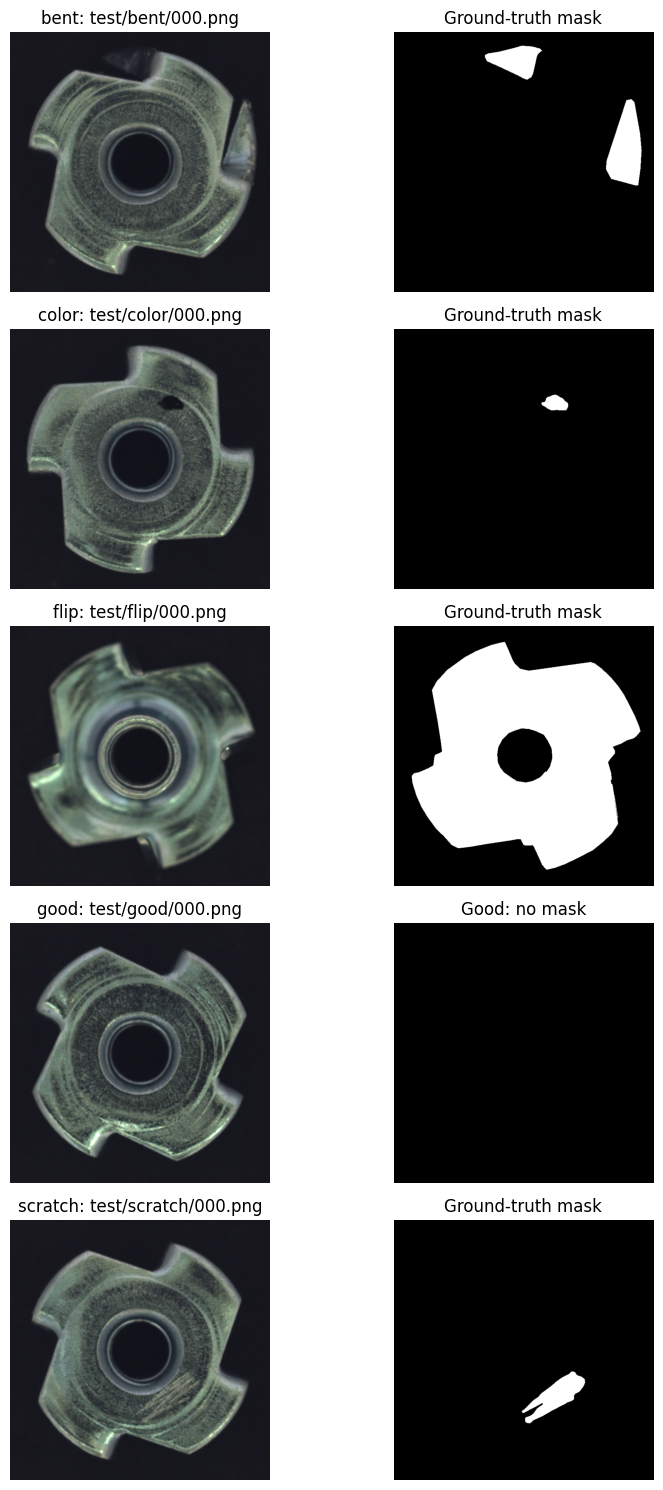

In [3]:
inventory = inspect_dataset(DATASET_DIR, MIN_MASK_AREA)
print(
    f"Total: {len(inventory)} | Good: {(~inventory.is_defective).sum()} | "
    f"Defective: {inventory.is_defective.sum()}"
)
display(
    inventory.groupby(["original_split", "category"]).size().rename("images").to_frame()
)
display(inventory.groupby("category").size().rename("images").to_frame())
inventory.assign(boxes=inventory.boxes.map(json.dumps)).to_csv(
    OUTPUT_DIR / "dataset_inventory.csv", index=False
)
examples = inventory.groupby("category", sort=True).head(1)
fig, axes = plt.subplots(
    len(examples), 2, figsize=(9, 3 * len(examples)), squeeze=False
)
for axes_row, row in zip(axes, examples.itertuples()):
    image = read_rgb(DATASET_DIR / row.image_path)
    axes_row[0].imshow(image)
    axes_row[0].set_title(f"{row.category}: {row.image_path}")
    mask = (
        read_mask(DATASET_DIR / row.mask_path)
        if row.is_defective
        else np.zeros(image.shape[:2], dtype=np.uint8)
    )
    axes_row[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes_row[1].set_title("Ground-truth mask" if row.is_defective else "Good: no mask")
    for axis in axes_row:
        axis.axis("off")
plt.tight_layout()
plt.show()

## 5 — Convert masks into bounding boxes

`src/annotations.py::mask_to_boxes` thresholds nonzero pixels, finds 8-connected
components, and keeps regions with at least 9 foreground pixels. Boxes use
exclusive `(x1, y1, x2, y2)` edges, so a component reaching the final column has
`x2 = image_width`. YOLO stores normalized center-x, center-y, width, height.
The conversion is checked by a round trip; normal images will get empty labels.
These are mask-derived region boxes, not expert-annotated object instances.


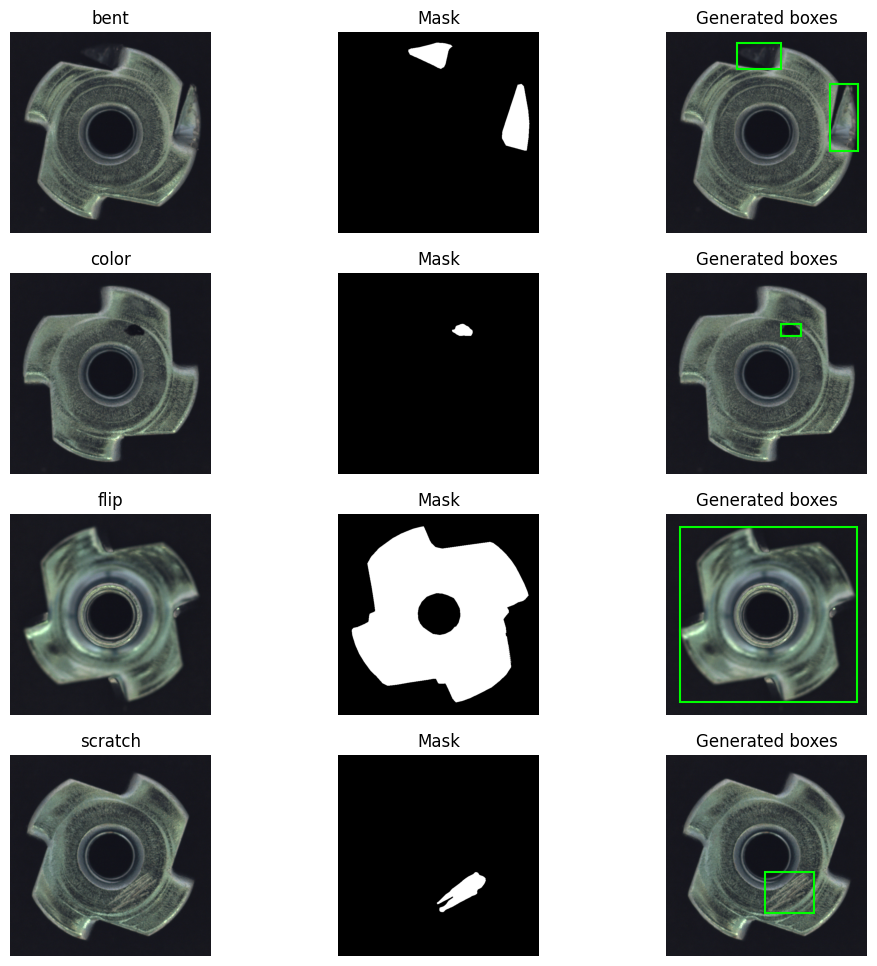

In [4]:
defect_examples = inventory[inventory.is_defective].groupby("category").head(1)
fig, axes = plt.subplots(
    len(defect_examples), 3, figsize=(12, 3 * len(defect_examples)), squeeze=False
)
for axes_row, row in zip(axes, defect_examples.itertuples()):
    image = read_rgb(DATASET_DIR / row.image_path)
    mask = read_mask(DATASET_DIR / row.mask_path)
    normalized = boxes_to_yolo(row.boxes, row.width, row.height)
    restored = yolo_to_boxes(normalized, row.width, row.height)
    np.testing.assert_allclose(restored, row.boxes, atol=1e-3)
    axes_row[0].imshow(image)
    axes_row[1].imshow(mask, cmap="gray")
    draw_boxes(axes_row[2], image, row.boxes, "lime")
    for axis, title in zip(axes_row, [row.category, "Mask", "Generated boxes"]):
        axis.set_title(title)
        axis.axis("off")
save_figure(fig, OUTPUT_DIR / "predictions" / "annotation_check.png")
plt.show()

## 6 — Split dataset 80/20

Both calls use `train_test_split(random_state=42)`. Stratification first uses the
original category (which includes `good`); if too small it falls back to status,
then explicitly logs that stratification is unavailable. The original dataset
is pooled **before** splitting. Validation is taken only from development.
The manifest records hashes and source paths, including original train/test
provenance. Identical file content is refused to prevent duplicate leakage.
Near-duplicate views and production lots need a separate grouped split in a real deployment.


In [5]:
manifest = split_dataset(inventory, TEST_RATIO, VAL_RATIO, SEED)
manifest_csv = manifest.assign(boxes=manifest.boxes.map(json.dumps))
manifest_path = OUTPUT_DIR / "split_manifest.csv"
if manifest_path.exists():
    previous = pd.read_csv(manifest_path, keep_default_na=False)
    pd.testing.assert_frame_equal(previous, manifest_csv, check_dtype=False)
manifest_csv.to_csv(manifest_path, index=False)
summary = split_summary(manifest)
summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
display(summary)
display(pd.crosstab(manifest.category, manifest.split))
train_rows = manifest[manifest.split == "train"].copy()
validation_rows = manifest[manifest.split == "val"].copy()
test_rows = manifest[manifest.split == "test"].copy()
assert set(train_rows.sha256).isdisjoint(test_rows.sha256)
assert set(validation_rows.sha256).isdisjoint(test_rows.sha256)
prepared_dir = prepare_yolo(
    manifest, DATASET_DIR, ROOT / "data" / "prepared", DATA_YAML, MIN_MASK_AREA
)
data_config = yaml.safe_load(DATA_YAML.read_text())
display(data_config)
print("Prepared images:", prepared_dir.relative_to(ROOT))

,Dataset,Images,Good,Defective
0,Training/development (80%),268,194,74
1,Testing (20%),67,48,19
2,Training only (within development),234,169,65
3,Validation (within development),34,25,9


split,test,train,val
category,,,
bent,5,17,3
color,4,16,2
flip,5,16,2
good,48,169,25
scratch,5,16,2


{"directory": "C:\\metal-nut-defect-detection\\data\\prepared\\e23c17458f1a7951", "images": 335, "event": "yolo_dataset_written", "timestamp": "2026-10-26T06:24:06.775508Z"}


{'path': 'C:/metal-nut-defect-detection/data/prepared/e23c17458f1a7951',
 'train': 'images/train',
 'val': 'images/val',
 'test': 'images/test',
 'names': {0: 'defect'}}

Prepared images: data\prepared\e23c17458f1a7951


## 7 — Visualize training samples

Read the saved YOLO labels, not just the in-memory boxes, to check alignment.
Preview reflected training images and transformed boxes. Unlike rotation of a
border-touching region, reflection preserves all pixels without cropping.


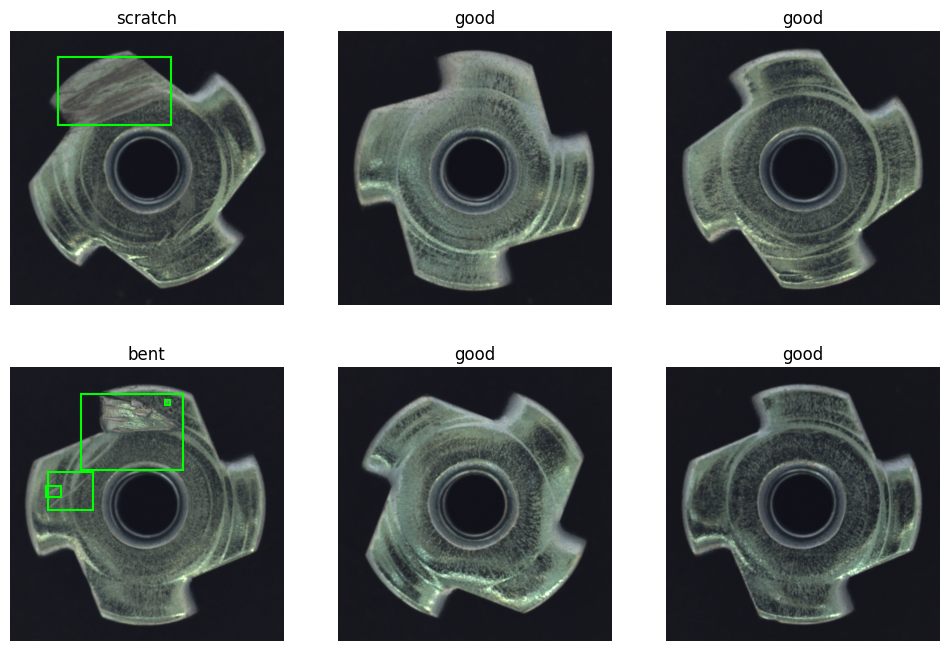

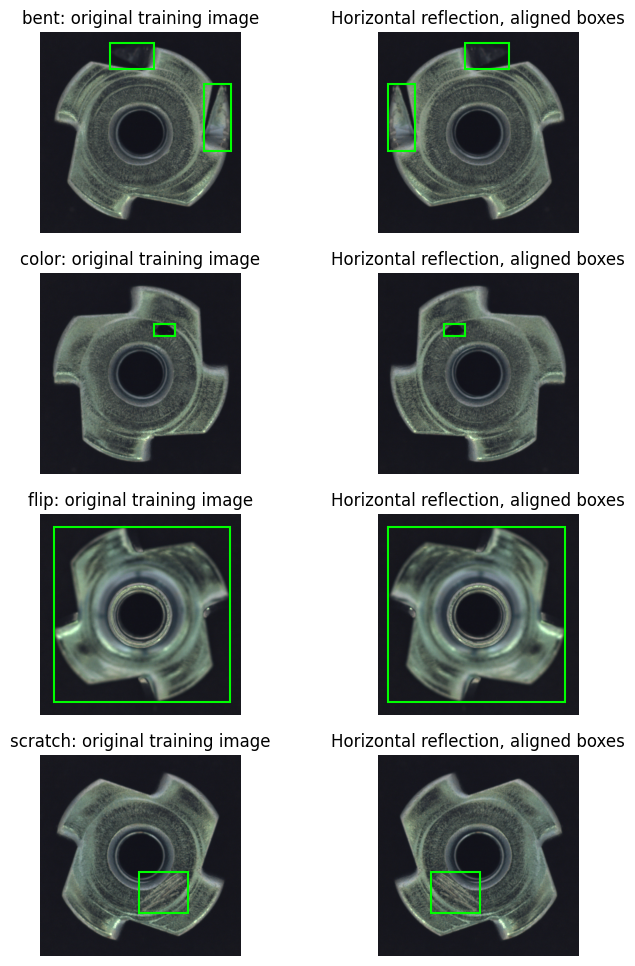

In [6]:
samples = train_rows.sample(min(6, len(train_rows)), random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for axis in axes.flat:
    axis.axis("off")
for axis, row in zip(axes.flat, samples.itertuples()):
    image = read_rgb(DATASET_DIR / row.image_path)
    label_path = prepared_dir / "labels" / "train" / f"{row.image_id}.txt"
    text = label_path.read_text().strip()
    labels = np.array(
        [list(map(float, line.split()[1:])) for line in text.splitlines()]
    ).reshape(-1, 4)
    boxes = yolo_to_boxes(labels, row.width, row.height)
    np.testing.assert_allclose(boxes, np.asarray(row.boxes).reshape(-1, 4), atol=1e-3)
    draw_boxes(axis, image, boxes, "lime")
    axis.set_title(row.category)
save_figure(fig, OUTPUT_DIR / "predictions" / "training_samples.png")
plt.show()

preview = train_rows[train_rows.is_defective].groupby("category").head(1)
fig, axes = plt.subplots(len(preview), 2, figsize=(8, 3 * len(preview)), squeeze=False)
for axes_row, row in zip(axes, preview.itertuples()):
    image = read_rgb(DATASET_DIR / row.image_path)
    reflected = np.asarray(row.boxes, dtype=np.float32).reshape(-1, 4).copy()
    reflected[:, [0, 2]] = row.width - reflected[:, [2, 0]]
    draw_boxes(axes_row[0], image, row.boxes, "lime")
    draw_boxes(axes_row[1], image[:, ::-1], reflected, "lime")
    axes_row[0].set_title(f"{row.category}: original training image")
    axes_row[1].set_title("Horizontal reflection, aligned boxes")
save_figure(fig, OUTPUT_DIR / "predictions" / "augmentation_preview.png")
plt.show()

## 8 — Load YOLO model

YOLOv8n uses the nano architecture to reduce parameter count and compute relative
to larger detectors. This is a practical CPU/edge starting point; actual target
hardware latency and missed-small-defect rates still need measurement. Pretrained
COCO features are fine-tuned for the single defect class. Initial weights may
download from Ultralytics on the first run; internet access is needed once.


In [7]:
pretrained_path = ROOT / "models" / MODEL
initial_model = YOLO(str(pretrained_path))
initial_model.info()
from src.dataset import file_hash

config["pretrained_sha256"] = file_hash(pretrained_path)
(OUTPUT_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2))

YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


1147

## 9 — Train the baseline model

Train baseline and the **predeclared** augmentation run now so the complete model
choice is frozen before section 10 exposes the test set. Both start from the same
pretrained checkpoint and seed, use the same architecture, 640 input, optimizer,
batch size, 50-epoch budget, and train/validation images. Only `fliplr` changes.

Ultralytics saves `best.pt`, `last.pt`, `results.csv`, `results.png`, validation
plots and `args.yaml` under the run directory. Best epochs and the final model
are selected by **validation mAP@0.5:0.95**; ties favor baseline. Early stopping
is disabled (`patience=0`) to keep both budgets equal. No test labels are read
by training or selection. Native training plots are copied for review.


{"experiment": "baseline", "event": "training_started", "timestamp": "2026-10-26T06:24:08.934156Z"}


New https://pypi.org/project/ultralytics/8.4.189 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.51  Python-3.11.9 torch-2.7.1+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\metal-nut-defect-detection\configs\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\metal-nut-defect-detection\models\yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=baseline, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=0, perspective=0

Overriding model.yaml nc=80 with nc=1


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.1it/s 1.0s

                   all         34         12      0.964      0.583      0.638       0.43


Speed: 0.7ms preprocess, 13.9ms inference, 0.0ms loss, 0.9ms postprocess per image


Results saved to C:\metal-nut-defect-detection\results\runs\20261026T062357976003Z\baseline_validation


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,391.220,0.07267,0.12312,0.73863,0.96239,0.41667,0.52006,0.36227,0.55158,0.53629,0.71870,0.000109,0.000109,0.000109
46,47,398.649,0.06504,0.13221,0.71269,0.97066,0.41667,0.52007,0.36191,0.54699,0.53145,0.71633,0.000089,0.000089,0.000089
47,48,406.176,0.07099,0.12512,0.72592,0.97292,0.41667,0.52213,0.36289,0.54605,0.53699,0.71649,0.000069,0.000069,0.000069
48,49,413.732,0.06224,0.10845,0.71982,0.97436,0.41667,0.51616,0.35681,0.54257,0.53446,0.71100,0.000050,0.000050,0.000050
49,50,421.342,0.06158,0.10647,0.73892,0.97018,0.41667,0.51800,0.35769,0.53902,0.53265,0.70866,0.000030,0.000030,0.000030


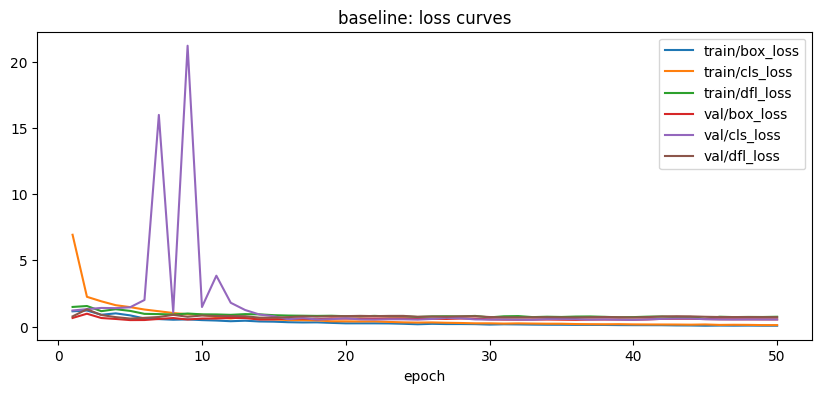

{"experiment": "augmented", "event": "training_started", "timestamp": "2026-10-26T06:31:25.716174Z"}


New https://pypi.org/project/ultralytics/8.4.189 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.51  Python-3.11.9 torch-2.7.1+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\metal-nut-defect-detection\configs\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\metal-nut-defect-detection\models\yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=augmented, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=0, perspective=

Overriding model.yaml nc=80 with nc=1


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 4.0it/s 1.2s

                   all         34         12      0.826      0.796      0.863      0.628


Speed: 0.9ms preprocess, 14.0ms inference, 0.0ms loss, 1.4ms postprocess per image


Results saved to C:\metal-nut-defect-detection\results\runs\20261026T062357976003Z\augmented_validation


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,393.401,0.14400,0.22365,0.75819,0.87808,0.66667,0.73058,0.52669,0.38121,0.47926,0.57057,0.000109,0.000109,0.000109
46,47,401.262,0.13487,0.24209,0.72955,0.87859,0.66667,0.74053,0.52148,0.38000,0.46144,0.56216,0.000089,0.000089,0.000089
47,48,409.411,0.13277,0.24103,0.74432,0.87920,0.66667,0.74338,0.52155,0.37579,0.45327,0.55262,0.000069,0.000069,0.000069
48,49,418.667,0.11916,0.21205,0.73598,0.87972,0.66667,0.74424,0.52220,0.37453,0.44090,0.54867,0.000050,0.000050,0.000050
49,50,428.825,0.11861,0.20497,0.75314,0.88003,0.66667,0.75060,0.52882,0.37558,0.43898,0.55018,0.000030,0.000030,0.000030


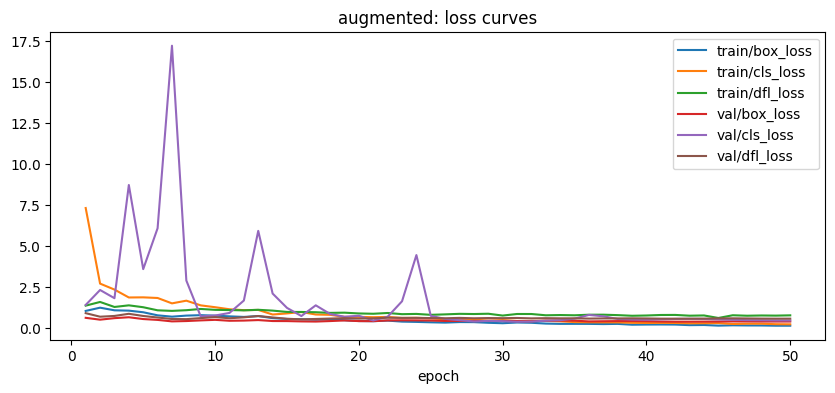

,validation_map50,validation_map50_95
experiment,,
baseline,0.638413,0.430239
augmented,0.862667,0.628269


{"experiment": "augmented", "criterion": "validation mAP@0.5:0.95; baseline wins ties", "weights": "results\\runs\\20261026T062357976003Z\\augmented\\weights\\best.pt", "validation_metrics": [{"experiment": "baseline", "validation_map50": 0.6384129353233832, "validation_map50_95": 0.43023943017830096}, {"experiment": "augmented", "validation_map50": 0.8626666666666667, "validation_map50_95": 0.6282691543836281}], "frozen_before_test": true, "event": "selection_frozen", "timestamp": "2026-10-26T06:38:45.066115Z"}


In [8]:
train_arguments = dict(
    data=str(DATA_YAML),
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    epochs=EPOCHS,
    device=DEVICE,
    workers=WORKERS,
    seed=SEED,
    deterministic=True,
    optimizer="AdamW",
    lr0=0.001,
    patience=0,
    close_mosaic=0,
    project=str(RUN_DIR),
    plots=True,
    save=True,
    exist_ok=False,
    val=True,
    amp=DEVICE != "cpu",
    rect=False,
    augmentations=[],  # Disable optional Albumentations defaults as well.
)
best_paths, validation_metrics = {}, []
for name, augmentation in EXPERIMENTS.items():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = YOLO(str(pretrained_path))
    log.info("training_started", experiment=name)
    model.train(name=name, **train_arguments, **augmentation)
    run = Path(model.trainer.save_dir)
    best_paths[name] = run / "weights" / "best.pt"
    if not best_paths[name].is_file():
        raise FileNotFoundError(best_paths[name])
    best_model = YOLO(str(best_paths[name]))
    validation = best_model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=WORKERS,
        conf=AP_CONFIDENCE,
        iou=NMS_IOU,
        max_det=MAX_DETECTIONS,
        rect=False,
        augment=False,
        plots=True,
        project=str(RUN_DIR),
        name=f"{name}_validation",
    )
    validation_metrics.append(
        {
            "experiment": name,
            "validation_map50": validation.box.map50,
            "validation_map50_95": validation.box.map,
        }
    )
    history = pd.read_csv(run / "results.csv")
    history.columns = history.columns.str.strip()
    display(history.tail())
    columns = [column for column in history if "loss" in column]
    axes = history.plot(
        x="epoch", y=columns, figsize=(10, 4), title=f"{name}: loss curves"
    )
    save_figure(axes.figure, OUTPUT_DIR / "training_curves" / f"{name}_loss.png")
    plt.show()
    if (run / "results.png").exists():
        shutil.copy2(
            run / "results.png", OUTPUT_DIR / "training_curves" / f"{name}_results.png"
        )

validation_table = pd.DataFrame(validation_metrics).set_index("experiment")
display(validation_table)
selected_name = validation_table.validation_map50_95.idxmax()
selection = {
    "experiment": selected_name,
    "criterion": "validation mAP@0.5:0.95; baseline wins ties",
    "weights": str(best_paths[selected_name].relative_to(ROOT)),
    "validation_metrics": validation_table.reset_index().to_dict("records"),
    "frozen_before_test": True,
}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2))
shutil.copy2(best_paths[selected_name], ROOT / "models" / "metal_nut_detector.pt")
log.info("selection_frozen", **selection)

## 10 — Test using the held-out 20%

Evaluate **every** held-out image, including good images with no ground-truth
boxes. Ultralytics computes AP from a low-confidence prediction pool at IoU 0.5
and 0.5:0.95. Separately, one-to-one, confidence-ordered matching at IoU ≥0.5
gives TP/FP/FN and precision/recall at the **fixed 0.25 operating confidence**.
These P/R values are not the library's test-optimized max-F1 P/R values.

NMS IoU (0.7) is distinct from matching IoU (0.5). Both experiments use exactly
the same settings, no test-time augmentation, FP32 and square letterboxing.
After test exposure, any new tuning requires a fresh independent test set.


In [9]:
def evaluate_test(name):
    detector = YOLO(str(best_paths[name]))
    ap = detector.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=WORKERS,
        conf=AP_CONFIDENCE,
        iou=NMS_IOU,
        max_det=MAX_DETECTIONS,
        rect=False,
        augment=False,
        half=False,
        plots=True,
        project=str(RUN_DIR),
        name=f"{name}_test",
    )
    records, predictions = [], {}
    for row in test_rows.itertuples():
        prediction = detector.predict(
            source=str(DATASET_DIR / row.image_path),
            imgsz=IMAGE_SIZE,
            conf=CONFIDENCE,
            iou=NMS_IOU,
            max_det=MAX_DETECTIONS,
            device=DEVICE,
            rect=False,
            augment=False,
            half=False,
            verbose=False,
        )[0]
        boxes = prediction.boxes.xyxy.cpu().numpy()
        scores = prediction.boxes.conf.cpu().numpy()
        detected = np.column_stack((boxes, scores)).astype(np.float32)
        predictions[row.image_id] = detected
        matched = match_detections(row.boxes, detected, MATCH_IOU)
        records.append(
            {
                "image_id": row.image_id,
                "category": row.category,
                "is_defective": row.is_defective,
                **{key: matched[key] for key in ("tp", "fp", "fn")},
            }
        )
    per_image = pd.DataFrame(records)
    assert len(per_image) == len(test_rows)
    assert set(per_image.image_id) == set(test_rows.image_id)
    totals = per_image[["tp", "fp", "fn"]].sum()
    tp, fp, fn = map(int, totals)
    metrics = {
        "experiment": name,
        "test_images": len(test_rows),
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "map50": float(ap.box.map50),
        "map50_95": float(ap.box.map),
        "tp": tp,
        "fp": fp,
        "fn": fn,
    }
    per_image.to_csv(OUTPUT_DIR / f"{name}_per_image.csv", index=False)
    (OUTPUT_DIR / f"{name}_predictions.json").write_text(
        json.dumps({key: value.tolist() for key, value in predictions.items()})
    )
    log.info("held_out_evaluation_complete", **metrics)
    return metrics, per_image, predictions


test_metrics, image_metrics, test_predictions = {}, {}, {}
for name in EXPERIMENTS:
    test_metrics[name], image_metrics[name], test_predictions[name] = evaluate_test(
        name
    )
metrics_table = pd.DataFrame(test_metrics.values()).set_index("experiment")
metrics_table.to_csv(OUTPUT_DIR / "metrics.csv")
display(metrics_table)
print("Final model remains the validation-selected model:", selected_name)

Ultralytics 8.4.51  Python-3.11.9 torch-2.7.1+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)


Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.20.1 ms, read: 48.13.0 MB/s, size: 487.6 KB)


val: Scanning C:\metal-nut-defect-detection\data\prepared\e23c17458f1a7951\labels\test... 28 images, 9 backgrounds, 0 corrupt: 42% ━━━━━─────── 28/67 75.9it/s 0.1s<0.5s

val: Scanning C:\metal-nut-defect-detection\data\prepared\e23c17458f1a7951\labels\test... 67 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 342.6it/s 0.2s

...

Speed: 0.6ms preprocess, 8.1ms inference, 0.0ms loss, 1.3ms postprocess per image


Results saved to C:\metal-nut-defect-detection\results\runs\20261026T062357976003Z\augmented_test


{"experiment": "augmented", "test_images": 67, "precision": 0.9166666666666666, "recall": 0.4583333333333333, "map50": 0.651614241558397, "map50_95": 0.4419394147011225, "tp": 11, "fp": 1, "fn": 13, "event": "held_out_evaluation_complete", "timestamp": "2026-10-26T06:38:57.449949Z"}


,test_images,precision,recall,map50,map50_95,tp,fp,fn
experiment,,,,,,,,
baseline,67,0.846154,0.458333,0.646565,0.479128,11,2,13
augmented,67,0.916667,0.458333,0.651614,0.441939,11,1,13


Final model remains the validation-selected model: augmented


## 11 — Test image visualization

Use held-out samples from each available category, including `good`. Ground truth
is green; predictions are red and show confidence. The original image is included
as a separate panel so boxes do not obscure inspection.


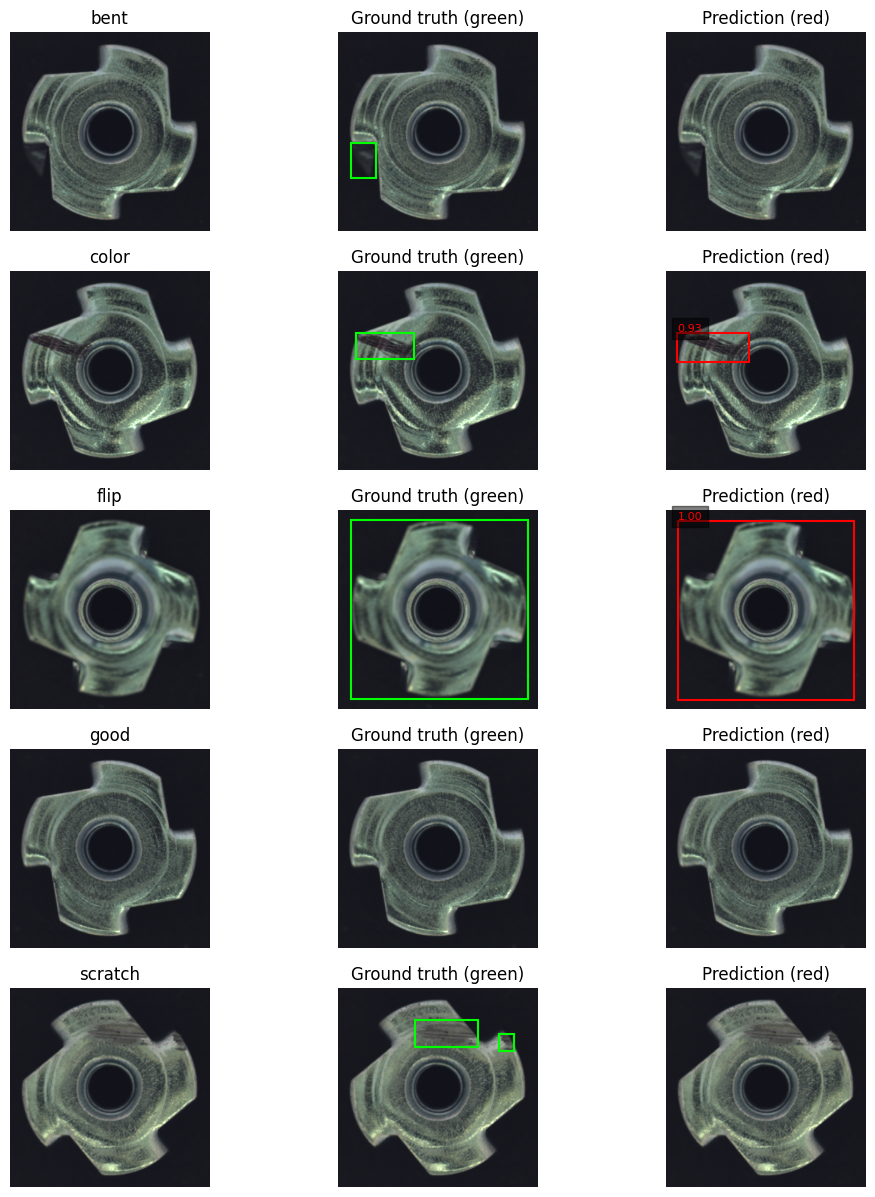

In [10]:
test_samples = test_rows.groupby("category", sort=True).head(1)
fig, axes = plt.subplots(
    len(test_samples), 3, figsize=(12, 3 * len(test_samples)), squeeze=False
)
for axes_row, row in zip(axes, test_samples.itertuples()):
    image = read_rgb(DATASET_DIR / row.image_path)
    predicted = test_predictions[selected_name][row.image_id]
    axes_row[0].imshow(image)
    draw_boxes(axes_row[1], image, row.boxes, "lime")
    draw_boxes(axes_row[2], image, predicted[:, :4], "red", predicted[:, 4])
    for axis, title in zip(
        axes_row, [row.category, "Ground truth (green)", "Prediction (red)"]
    ):
        axis.set_title(title)
        axis.axis("off")
save_figure(fig, OUTPUT_DIR / "predictions" / "held_out_examples.png")
plt.show()

## 12 — Failure case analysis

Show up to five real failing images for the validation-selected model, prioritizing
larger FP+FN counts. Explanations below are **hypotheses for visual review**, not
proven root causes. Small means mask-derived box area <0.5% of image area; a
localization candidate has an unmatched prediction/truth overlap between 0.1
and the matching IoU. No thresholds or training choices change after this analysis.
If fewer than five failing images exist, show and state the actual number.


10 genuine failing images; showing 5.


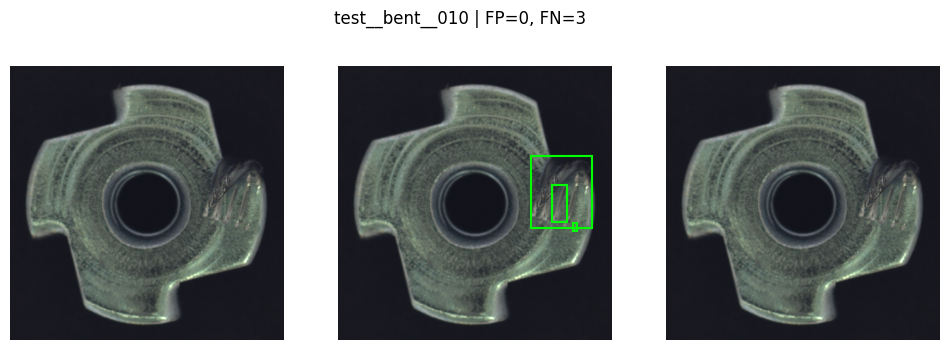

Missed region: weak contrast or ambiguous shape may hide the defect. At least one missed box is small; resizing may remove detail.


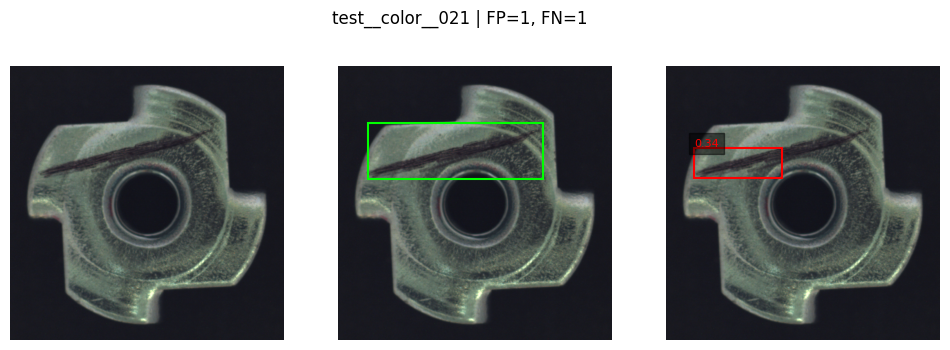

False positive: reflections or normal edges may resemble a defect. Missed region: weak contrast or ambiguous shape may hide the defect. Partial overlap suggests a localization error; inspect box extent.


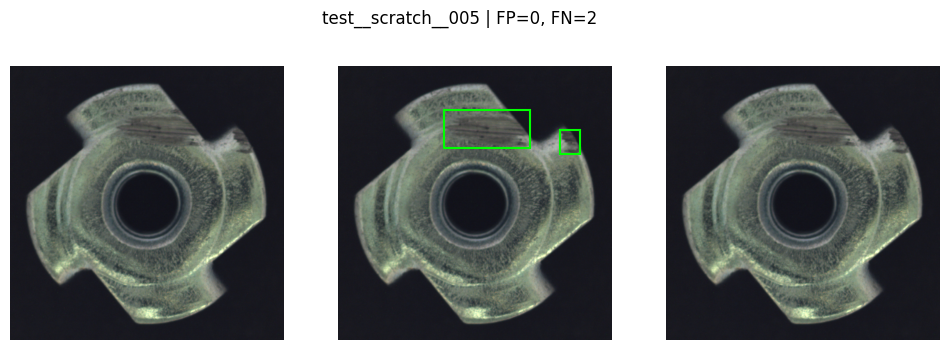

Missed region: weak contrast or ambiguous shape may hide the defect.


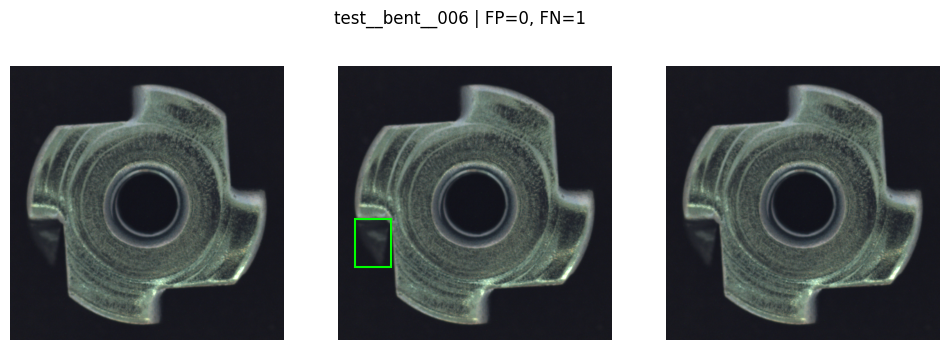

Missed region: weak contrast or ambiguous shape may hide the defect.


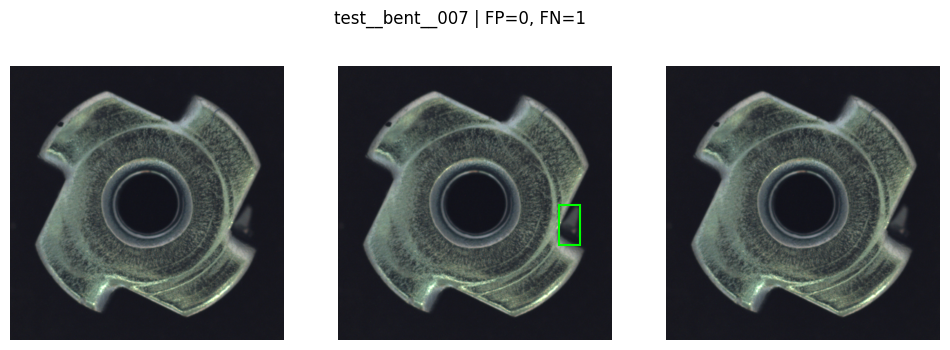

Missed region: weak contrast or ambiguous shape may hide the defect.


1271

In [11]:
failures = image_metrics[selected_name].copy()
failures["errors"] = failures.fp + failures.fn
failures = failures[failures.errors > 0].sort_values(
    ["errors", "image_id"], ascending=[False, True]
)
print(f"{len(failures)} genuine failing images; showing {min(5, len(failures))}.")
if len(failures) < 5:
    print("Fewer than five genuine failures were observed; all are shown.")
failure_records = []
for number, failure in enumerate(failures.head(5).itertuples(), start=1):
    row = test_rows.set_index("image_id").loc[failure.image_id]
    image = read_rgb(DATASET_DIR / row.image_path)
    truth = np.asarray(row.boxes, dtype=np.float32).reshape(-1, 4)
    predicted = test_predictions[selected_name][failure.image_id]
    matches = match_detections(truth, predicted, MATCH_IOU)
    reasons = []
    if failure.fp:
        reasons.append(
            "False positive: reflections or normal edges may resemble a defect."
        )
    if failure.fn:
        reasons.append(
            "Missed region: weak contrast or ambiguous shape may hide the defect."
        )
        missed = truth[matches["missed_truth"]]
        area = np.prod(missed[:, 2:] - missed[:, :2], axis=1)
        if (area / (row.width * row.height) < 0.005).any():
            reasons.append(
                "At least one missed box is small; resizing may remove detail."
            )
    if matches["false_predictions"] and matches["missed_truth"]:
        overlap = box_iou(
            predicted[matches["false_predictions"], :4], truth[matches["missed_truth"]]
        )
        if ((overlap >= 0.1) & (overlap < MATCH_IOU)).any():
            reasons.append(
                "Partial overlap suggests a localization error; inspect box extent."
            )
    explanation = " ".join(reasons)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(image)
    axes[0].axis("off")
    draw_boxes(axes[1], image, truth, "lime")
    draw_boxes(axes[2], image, predicted[:, :4], "red", predicted[:, 4])
    fig.suptitle(f"{failure.image_id} | FP={failure.fp}, FN={failure.fn}")
    path = OUTPUT_DIR / "failure_cases" / f"{number:02}_{failure.image_id}.png"
    save_figure(fig, path)
    plt.show()
    print(explanation)
    failure_records.append(
        {
            "image_id": failure.image_id,
            "fp": failure.fp,
            "fn": failure.fn,
            "hypothesis": explanation,
            "figure": path.relative_to(OUTPUT_DIR).as_posix(),
        }
    )
(OUTPUT_DIR / "failure_cases").mkdir(exist_ok=True)
(OUTPUT_DIR / "failure_cases" / "analysis.json").write_text(
    json.dumps(failure_records, indent=2)
)

## 13 — Improvement experiment

The controlled experiment was trained in section 9 before either test result
was opened. This section compares its outcomes. The word `augmented` describes
the intervention, not a guaranteed improvement. Both models received the same
training/validation split and initialization; only horizontal reflection changed.

Measure CPU end-to-end prediction latency on the same preloaded test images,
including color conversion and the library's preprocessing/NMS but excluding
disk I/O, model loading and session startup. These are PyTorch CPU timings; the
next sections separately test ONNX. A single seeded run cannot establish statistical
significance, and the selected model remains the validation choice.


In [12]:
timing_images = [
    read_rgb(DATASET_DIR / row.image_path) for row in test_rows.head(10).itertuples()
]
cpu_timings = {}
for name in EXPERIMENTS:
    cpu_model = YOLO(str(best_paths[name]))
    image_index = [0]

    def cpu_prediction():
        image = timing_images[image_index[0] % len(timing_images)]
        image_index[0] += 1
        result = cpu_model.predict(
            cv2.cvtColor(image, cv2.COLOR_RGB2BGR),
            imgsz=IMAGE_SIZE,
            conf=CONFIDENCE,
            iou=NMS_IOU,
            max_det=MAX_DETECTIONS,
            device="cpu",
            rect=False,
            half=False,
            augment=False,
            verbose=False,
        )[0]
        return result.boxes.data.cpu().numpy()

    cpu_timings[name] = measure_latency(cpu_prediction, WARMUP_RUNS, MEASURED_RUNS)
    metrics_table.loc[name, "pytorch_cpu_total_mean_ms"] = cpu_timings[name]["mean_ms"]
metrics_table.to_csv(OUTPUT_DIR / "metrics.csv")
comparison = metrics_table[
    ["precision", "recall", "map50", "pytorch_cpu_total_mean_ms"]
].T
comparison.columns = ["Baseline", "Augmented"]
display(comparison)
delta = metrics_table.loc["augmented", "map50"] - metrics_table.loc["baseline", "map50"]
print(f"Augmentation changed test mAP@0.5 by {delta:+.4f}.")
print("Validation-selected final model:", selected_name)
print(
    "Review recall and CPU cost alongside AP; do not select a model using this test comparison."
)
(OUTPUT_DIR / "pytorch_cpu_timing.json").write_text(json.dumps(cpu_timings, indent=2))

,Baseline,Augmented
precision,0.846154,0.916667
recall,0.458333,0.458333
map50,0.646565,0.651614
pytorch_cpu_total_mean_ms,74.713547,65.324493


Augmentation changed test mAP@0.5 by +0.0050.
Validation-selected final model: augmented
Review recall and CPU cost alongside AP; do not select a model using this test comparison.


381

## 14 — ONNX export

Export the validation-selected checkpoint as FP32, static batch 1, opset 17,
without embedded NMS or graph simplification dependencies. Validate with ONNX
checker and CPU ONNX Runtime. Raw single-class YOLOv8 output is `[1, 5, N]`:
four pixel-space center/size coordinates and one class score (no objectness).

Use square RGB letterboxing, CHW float32 /255, confidence filtering, NMS, and
inverse padding/scale. Compare raw outputs against PyTorch for the same tensor,
then show decoded predictions on held-out images. A failed parity check stops
the workflow; it is not silently treated as a successful export.


Ultralytics 8.4.51  Python-3.11.9 torch-2.7.1+cu128 CPU (AMD Ryzen 7 7435HS)


Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs



PyTorch: starting from 'C:\metal-nut-defect-detection\models\metal_nut_detector.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.0 MB)



ONNX: starting export with onnx 1.23.2 opset 17...


ONNX: export success  1.2s, saved as 'C:\metal-nut-defect-detection\models\metal_nut_detector.onnx' (11.7 MB)



Export complete (1.9s)
Results saved to C:\metal-nut-defect-detection\models\metal_nut_detector.onnx
Predict:         yolo predict task=detect model=C:\metal-nut-defect-detection\models\metal_nut_detector.onnx imgsz=640 
Validate:        yolo val task=detect model=C:\metal-nut-defect-detection\models\metal_nut_detector.onnx imgsz=640 data=C:\metal-nut-defect-detection\configs\data.yaml  
Visualize:       https://netron.app


Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs


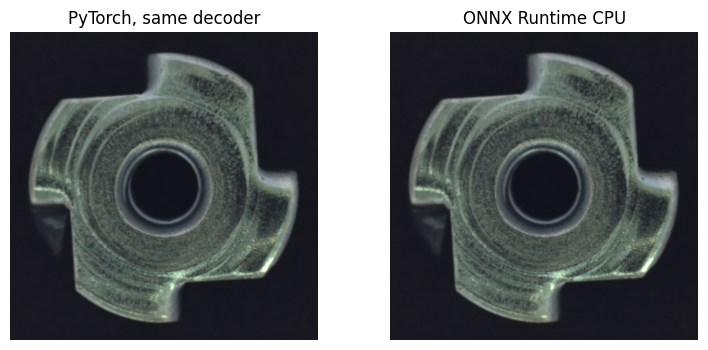

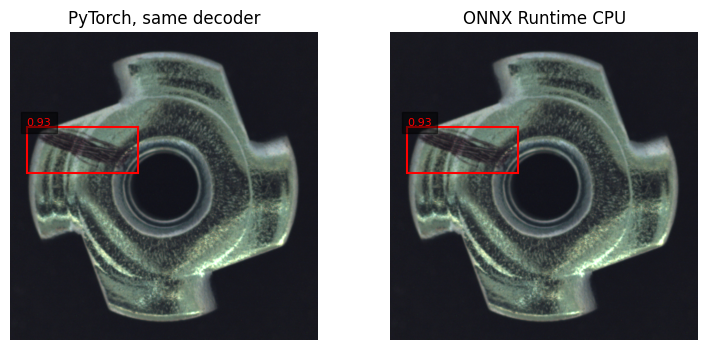

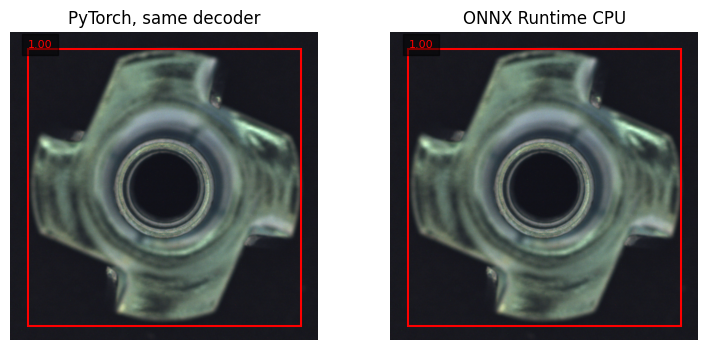

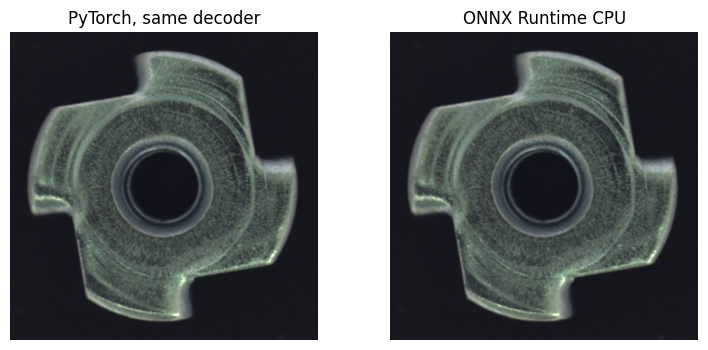

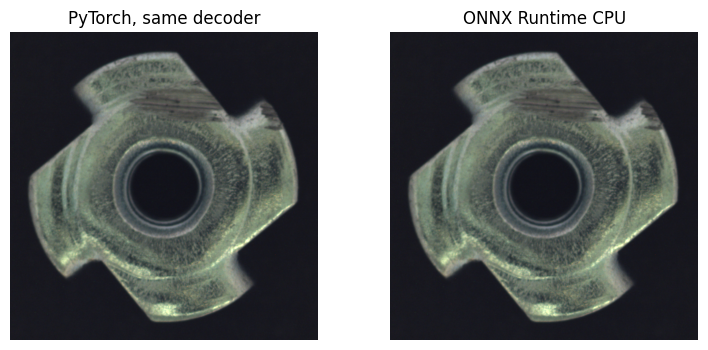

,image_id,raw_max_absolute_difference,onnx_detections,pytorch_detections,mean_best_box_iou
0,test__bent__006,0.001556,0,0,NaN
1,test__color__009,0.000702,1,1,1.0
2,test__flip__001,0.000793,1,1,1.0
3,test__good__004,0.000702,0,0,NaN
4,test__scratch__005,0.001221,0,0,NaN


{"path": "C:\\metal-nut-defect-detection\\models\\metal_nut_detector.onnx", "providers": ["CPUExecutionProvider"], "event": "onnx_validated", "timestamp": "2026-10-26T06:39:22.395185Z"}


In [13]:
selected_model = YOLO(str(ROOT / "models" / "metal_nut_detector.pt"))
exported = Path(
    selected_model.export(
        format="onnx",
        imgsz=IMAGE_SIZE,
        batch=1,
        dynamic=False,
        half=False,
        simplify=False,
        nms=False,
        opset=17,
        device="cpu",
    )
)
onnx_path = ROOT / "models" / "metal_nut_detector.onnx"
if exported.resolve() != onnx_path.resolve():
    shutil.copy2(exported, onnx_path)
onnx.checker.check_model(str(onnx_path))
options = ort.SessionOptions()
options.intra_op_num_threads = CPU_THREADS
options.inter_op_num_threads = 1
options.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
session = ort.InferenceSession(
    str(onnx_path), sess_options=options, providers=["CPUExecutionProvider"]
)
assert session.get_inputs()[0].shape == [1, 3, IMAGE_SIZE, IMAGE_SIZE]
input_name = session.get_inputs()[0].name
pytorch_model = YOLO(str(ROOT / "models" / "metal_nut_detector.pt"))
pytorch_model.fuse()
pytorch_model.model.cpu().float().eval()
parity_rows = []
parity_samples = test_rows.groupby("category", sort=True).head(1)
for row in parity_samples.itertuples():
    image = read_rgb(DATASET_DIR / row.image_path)
    tensor, transform = preprocess(image, IMAGE_SIZE)
    onnx_raw = session.run(None, {input_name: tensor})[0]
    with torch.inference_mode():
        pytorch_raw = pytorch_model.model(torch.from_numpy(tensor))
        if isinstance(pytorch_raw, (tuple, list)):
            pytorch_raw = pytorch_raw[0]
        pytorch_raw = pytorch_raw.cpu().numpy()
    np.testing.assert_allclose(onnx_raw, pytorch_raw, rtol=1e-3, atol=1e-3)
    onnx_boxes = decode(onnx_raw, transform, CONFIDENCE, NMS_IOU, MAX_DETECTIONS)
    torch_boxes = decode(pytorch_raw, transform, CONFIDENCE, NMS_IOU, MAX_DETECTIONS)
    overlap = box_iou(onnx_boxes[:, :4], torch_boxes[:, :4])
    parity_rows.append(
        {
            "image_id": row.image_id,
            "raw_max_absolute_difference": float(
                np.max(np.abs(onnx_raw - pytorch_raw))
            ),
            "onnx_detections": len(onnx_boxes),
            "pytorch_detections": len(torch_boxes),
            "mean_best_box_iou": float(overlap.max(axis=1).mean())
            if overlap.size
            else None,
        }
    )
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    draw_boxes(axes[0], image, torch_boxes[:, :4], "red", torch_boxes[:, 4])
    draw_boxes(axes[1], image, onnx_boxes[:, :4], "red", onnx_boxes[:, 4])
    axes[0].set_title("PyTorch, same decoder")
    axes[1].set_title("ONNX Runtime CPU")
    save_figure(fig, OUTPUT_DIR / "predictions" / f"onnx_{row.image_id}.png")
    plt.show()
parity_table = pd.DataFrame(parity_rows)
parity_table.to_csv(OUTPUT_DIR / "parity.csv", index=False)
display(parity_table)
onnx_status = "exported; checker, CPU load and raw-output parity passed"
log.info("onnx_validated", path=str(onnx_path), providers=session.get_providers())

## 15 — CPU benchmarking

Time a warmed CPUExecutionProvider session with `time.perf_counter()`. Model-only
means `session.run` on an already prepared tensor. Total means preprocessing +
inference + confidence filtering/NMS and coordinate recovery on preloaded RGB
images. Neither includes disk/camera I/O, startup, or drawing. Cycle through the
same images for repeated total measurements. FPS is 1000/mean latency, a serial
throughput approximation. Record actual host CPU; no Raspberry Pi claim is made.


In [14]:
cpu_model_name = platform.processor() or platform.machine()
if sys.platform == "win32":
    import winreg

    with winreg.OpenKey(
        winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0"
    ) as key:
        cpu_model_name = winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()

benchmark_images = timing_images
benchmark_tensors = [preprocess(image, IMAGE_SIZE)[0] for image in benchmark_images]
tensor_index = [0]
image_index = [0]


def model_only():
    tensor = benchmark_tensors[tensor_index[0] % len(benchmark_tensors)]
    tensor_index[0] += 1
    return session.run(None, {input_name: tensor})


def total_pipeline():
    image = benchmark_images[image_index[0] % len(benchmark_images)]
    image_index[0] += 1
    return predict_onnx(session, image, IMAGE_SIZE, CONFIDENCE, NMS_IOU, MAX_DETECTIONS)


benchmark = []
for scope, function in (
    ("model_only", model_only),
    ("preprocess_infer_postprocess", total_pipeline),
):
    timing = measure_latency(function, WARMUP_RUNS, MEASURED_RUNS)
    benchmark.append(
        {
            "scope": scope,
            "cpu_model": cpu_model_name,
            "platform": platform.platform(),
            "provider": session.get_providers()[0],
            "intra_op_threads": CPU_THREADS,
            "inter_op_threads": 1,
            "opencv_threads": 1,
            "image_size": IMAGE_SIZE,
            "batch": 1,
            "images_cycled": len(benchmark_images),
            "onnxruntime_version": ort.__version__,
            **timing,
        }
    )
benchmark_table = pd.DataFrame(benchmark)
benchmark_table.to_csv(OUTPUT_DIR / "cpu_benchmark.csv", index=False)
display(benchmark_table)

,scope,cpu_model,platform,provider,intra_op_threads,inter_op_threads,opencv_threads,image_size,batch,images_cycled,onnxruntime_version,mean_ms,median_ms,p95_ms,fps,warmup,runs
0,model_only,AMD Ryzen 7 7435HS,Windows-10-10.0.26300-SP0,CPUExecutionProvider,4,1,1,640,1,10,1.31.0,60.331077,61.02290,64.198360,16.575206,10,100
1,preprocess_infer_postprocess,AMD Ryzen 7 7435HS,Windows-10-10.0.26300-SP0,CPUExecutionProvider,4,1,1,640,1,10,1.31.0,63.309219,63.80395,66.313235,15.795488,10,100


## 16 — Final results

Tables and figures below are produced from this run only. The report saves the
split summary, both models' actual results, selected model, export status, CPU
timings, and up to five observed failures. It does not convert synthetic checks
or an unexecuted experiment into claimed performance.

Limitations: this is a small, custom supervised split with limited production
variation. A single connected defect may be divided into several instances;
box AP does not measure exact defect pixels. Small scratches can disappear at
640 input and reflective surfaces can cause false positives. Validate on new
manufacturing lots, establish a customer-specific missed-defect cost, and measure
the complete camera-to-controller path on the actual deployment device. Any
further improvements should be developed using validation or new labeled data.


In [15]:
display(summary)
display(metrics_table)
display(benchmark_table)
print("ONNX:", onnx_status)
print("Final model (validation choice):", selected_name)
print(
    "Failure cases saved:", len(failure_records), "of", len(failures), "failing images"
)


def markdown_table(frame, include_index=False):
    table = frame.reset_index() if include_index else frame.copy()
    lines = [
        "| " + " | ".join(map(str, table.columns)) + " |",
        "| " + " | ".join(["---"] * len(table.columns)) + " |",
    ]
    for values in table.itertuples(index=False, name=None):
        lines.append(
            "| "
            + " | ".join(
                f"{value:.4f}" if isinstance(value, float) else str(value)
                for value in values
            )
            + " |"
        )
    return "\n".join(lines)


report = [
    "# Actual experiment results",
    "Custom supervised split; not the official MVTec protocol.",
    markdown_table(summary),
    markdown_table(metrics_table, True),
    f"Final model: **{selected_name}**, chosen on validation before testing.",
    f"ONNX: {onnx_status}.",
    markdown_table(benchmark_table),
    f"Observed {len(failures)} failing test images; showing {len(failure_records)}.",
]
for failure in failure_records:
    report.extend(
        [f"![{failure['image_id']}]({failure['figure']})", failure["hypothesis"]]
    )
report.append(
    "Augmentation test mAP@0.5 change: " + f"{delta:+.4f}. "
    "One seeded run; inspect recall, FP/FN and latency before deployment. "
    "Final selection was based only on validation."
)
(OUTPUT_DIR / "final_results.md").write_text("\n\n".join(report), encoding="utf-8")
(OUTPUT_DIR / "run_status.json").write_text(
    json.dumps(
        {
            "status": "complete",
            "selected_model": selected_name,
            "onnx": onnx_status,
            "dataset_images": len(manifest),
            "test_images": len(test_rows),
            "failure_images": len(failures),
            "run_directory": str(RUN_DIR.relative_to(ROOT)),
        },
        indent=2,
    )
)
display(
    Markdown(
        "Actual results saved to `results/final_results.md`. Preserve the executed notebook."
    )
)

,Dataset,Images,Good,Defective
0,Training/development (80%),268,194,74
1,Testing (20%),67,48,19
2,Training only (within development),234,169,65
3,Validation (within development),34,25,9


,test_images,precision,recall,map50,map50_95,tp,fp,fn,pytorch_cpu_total_mean_ms
experiment,,,,,,,,,
baseline,67,0.846154,0.458333,0.646565,0.479128,11,2,13,74.713547
augmented,67,0.916667,0.458333,0.651614,0.441939,11,1,13,65.324493


,scope,cpu_model,platform,provider,intra_op_threads,inter_op_threads,opencv_threads,image_size,batch,images_cycled,onnxruntime_version,mean_ms,median_ms,p95_ms,fps,warmup,runs
0,model_only,AMD Ryzen 7 7435HS,Windows-10-10.0.26300-SP0,CPUExecutionProvider,4,1,1,640,1,10,1.31.0,60.331077,61.02290,64.198360,16.575206,10,100
1,preprocess_infer_postprocess,AMD Ryzen 7 7435HS,Windows-10-10.0.26300-SP0,CPUExecutionProvider,4,1,1,640,1,10,1.31.0,63.309219,63.80395,66.313235,15.795488,10,100


ONNX: exported; checker, CPU load and raw-output parity passed
Final model (validation choice): augmented
Failure cases saved: 5 of 10 failing images


Actual results saved to `results/final_results.md`. Preserve the executed notebook.

### Observations from the completed run

Both models completed 50 epochs. The augmentation model was selected using validation before test evaluation. On the 67-image test set, its precision is 0.9167, recall 0.4583, mAP@0.5 0.6516 and mAP@0.5:0.95 0.4419. Baseline mAP@0.5 is 0.6466 and mAP@0.5:0.95 is 0.4791.

The experiment has mixed results: it removed one false positive and increased mAP@0.5 by 0.0050, but did not recover additional defects and reduced stricter-IoU AP. Both models detected 11 of 24 labeled regions and missed 13 at confidence 0.25. This recall is insufficient for reliable manufacturing inspection. There are 10 failing test images for the selected model; five genuine examples are shown above. The color failure is a partial box over a long discoloration, while the scratch and bent examples demonstrate missed low-contrast or small regions.

ONNX checker, CPU loading and raw-output parity passed. On this AMD Ryzen 7 7435HS with four CPU inference threads, mean ONNX latency is 60.33 ms for the model and 63.31 ms including preprocessing/postprocessing, measured after 10 warm-ups over 100 runs. These are host measurements, not Raspberry Pi results. Further improvements need development-only experiments and a new independent final holdout; the exposed test set must not become a tuning set.
